In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter
from multifractal_networks.utils.motifs import MotifGenerator

# Load Network

In [4]:
filename = './test_networks/horses_individual_network.txt'
G = nx.read_edgelist(filename)

In [5]:
len(G)

236

In [6]:
2 * G.number_of_edges() / G.number_of_nodes()

4.38135593220339

In [7]:
for m_size in [2,3,5,6,7,10,11]:
    print(m_size,' k_max: ',int(np.log(len(G))/(np.log(m_size)))+1)

2  k_max:  8
3  k_max:  5
5  k_max:  4
6  k_max:  4
7  k_max:  3
10  k_max:  3
11  k_max:  3


# Init Fitter

**Note:** Triangles help in getting the group structure right.

In [8]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9,
        'triangle':9,
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.003533
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.008480


In [9]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 517},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 694},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 577},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 133},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 468},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 781},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 1095},
 {'name': 'four_loop',


# Grid Search

In [10]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,8]},
                {'m': 3,  'k': [1,5]},
                {'m': 5,  'k': [1,4]},
                {'m': 6,  'k': [1,4]},
                {'m': 7,  'k': [1,3]},],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'energy'
)

[I 2025-03-04 19:01:39,377] A new study created in memory with name: no-name-b44af0f7-603d-4c43-87f6-bd2b0c70e5d7


Grid Search requires 7 trials...


[I 2025-03-04 19:01:50,879] Trial 0 finished with value: 9.116745066882144 and parameters: {'m': 2, 'k': 7}. Best is trial 0 with value: 9.116745066882144.
[I 2025-03-04 19:02:02,632] Trial 1 finished with value: 10.417806247785323 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 9.116745066882144.
[I 2025-03-04 19:02:14,401] Trial 2 finished with value: 10.546592580687163 and parameters: {'m': 2, 'k': 2}. Best is trial 0 with value: 9.116745066882144.
[I 2025-03-04 19:02:26,495] Trial 3 finished with value: 9.90744063287815 and parameters: {'m': 2, 'k': 4}. Best is trial 0 with value: 9.116745066882144.
[I 2025-03-04 19:02:34,572] Trial 4 finished with value: 13.400677723002971 and parameters: {'m': 2, 'k': 1}. Best is trial 0 with value: 9.116745066882144.
[I 2025-03-04 19:02:43,200] Trial 5 finished with value: 7.908744261215162 and parameters: {'m': 2, 'k': 6}. Best is trial 5 with value: 7.908744261215162.
[I 2025-03-04 19:02:52,131] Trial 6 finished with value: 7.837

Grid Search requires 4 trials...


[I 2025-03-04 19:03:12,452] Trial 0 finished with value: 9.773655724655638 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 9.773655724655638.
[I 2025-03-04 19:03:37,945] Trial 1 finished with value: 9.031984438678748 and parameters: {'m': 3, 'k': 4}. Best is trial 1 with value: 9.031984438678748.
[I 2025-03-04 19:04:05,136] Trial 2 finished with value: 9.88843084710374 and parameters: {'m': 3, 'k': 2}. Best is trial 1 with value: 9.031984438678748.
[I 2025-03-04 19:04:25,052] Trial 3 finished with value: 12.671624091901723 and parameters: {'m': 3, 'k': 1}. Best is trial 1 with value: 9.031984438678748.
[I 2025-03-04 19:04:25,053] A new study created in memory with name: no-name-2c28972d-b748-4691-85ef-492116040edc


Grid Search requires 3 trials...


... (2 outputs left out)

[I 2025-03-04 19:08:03,383] Trial 0 finished with value: 9.784251896169517 and parameters: {'m': 6, 'k': 3}. Best is trial 0 with value: 9.784251896169517.
[I 2025-03-04 19:09:14,523] Trial 1 finished with value: 9.976839608301763 and parameters: {'m': 6, 'k': 2}. Best is trial 0 with value: 9.784251896169517.
[I 2025-03-04 19:10:04,889] Trial 2 finished with value: 10.213337624566256 and parameters: {'m': 6, 'k': 1}. Best is trial 0 with value: 9.784251896169517.
[I 2025-03-04 19:10:04,890] A new study created in memory with name: no-name-0cd3c159-ff5c-4d7a-8e88-f3573687fc27


Grid Search requires 2 trials...


[I 2025-03-04 19:11:36,925] Trial 0 finished with value: 9.809816969760401 and parameters: {'m': 7, 'k': 2}. Best is trial 0 with value: 9.809816969760401.
[I 2025-03-04 19:12:58,461] Trial 1 finished with value: 10.990588960899489 and parameters: {'m': 7, 'k': 1}. Best is trial 0 with value: 9.809816969760401.


Best parameters:  {'m': 2, 'k': 5}
Best energy:  7.8375224600440445
Best KL-divergence:  0.0016093741534070997
Best KLD augumented energy: 6.556892197742319
Best P matrix:
 [[9.77270467e-01 4.82597743e-19]
 [4.82597743e-19 7.89096107e-01]]
Best l vector:
 [0.53584087 0.46415913]


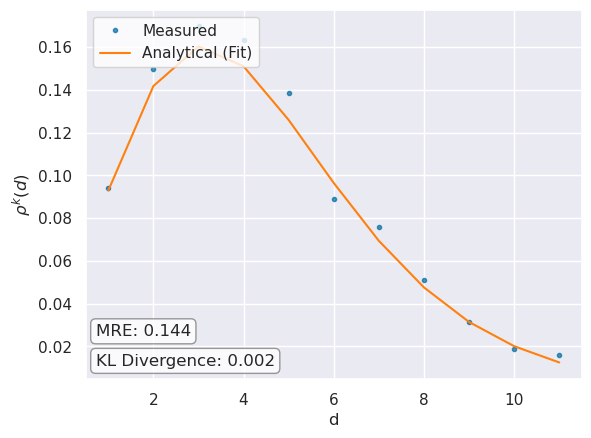

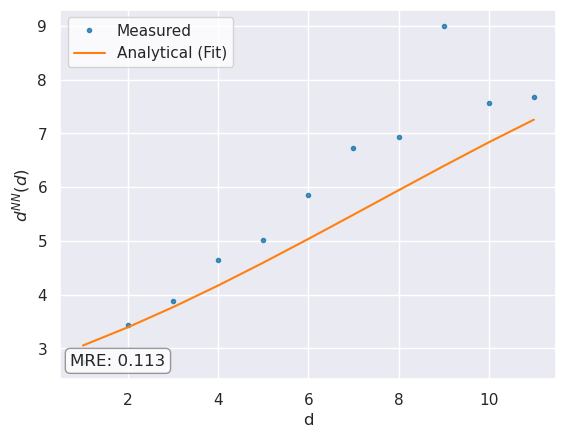

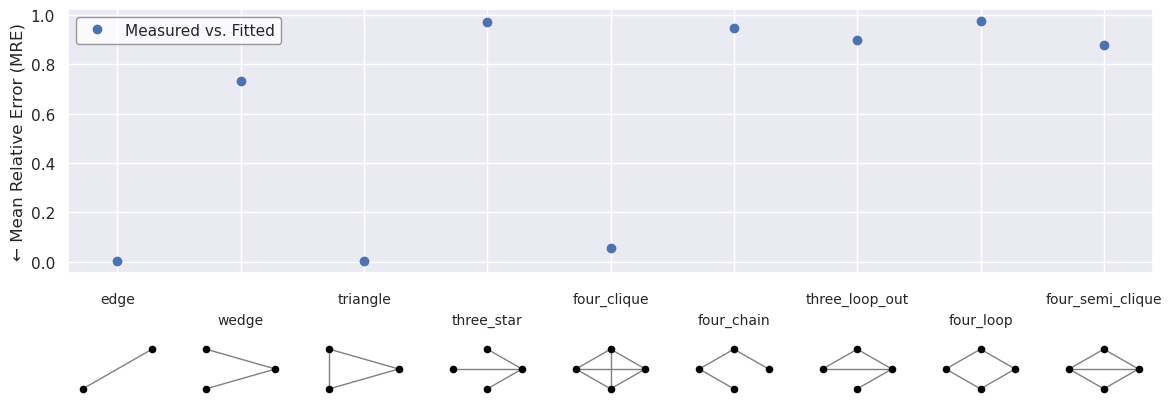

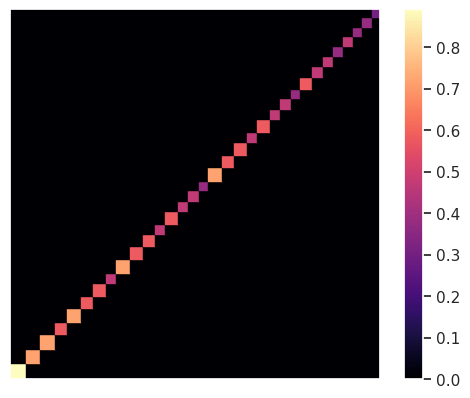

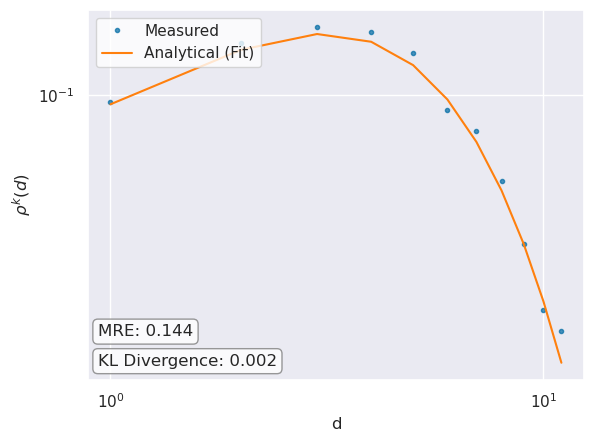

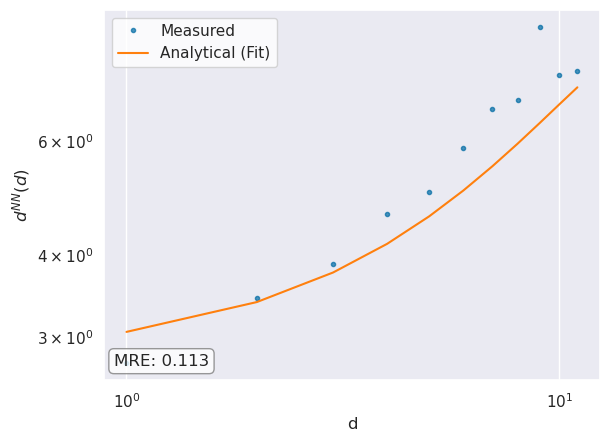

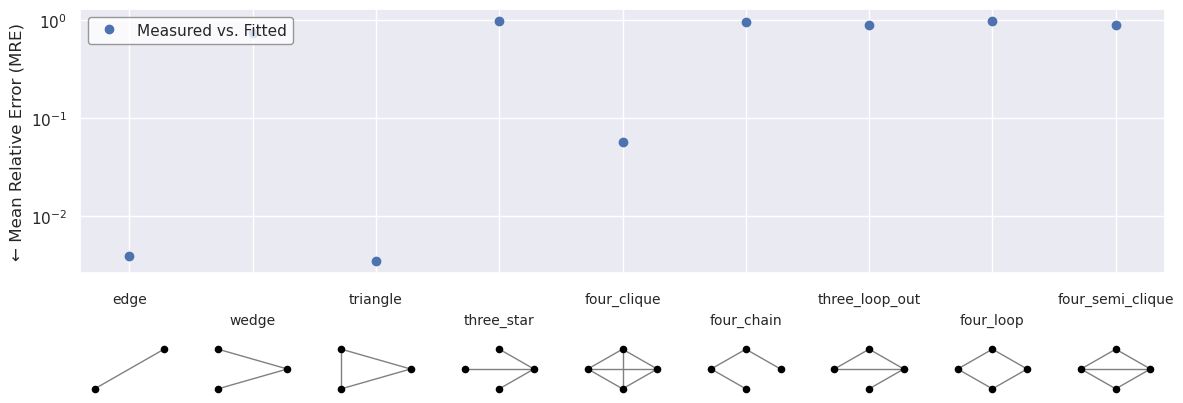

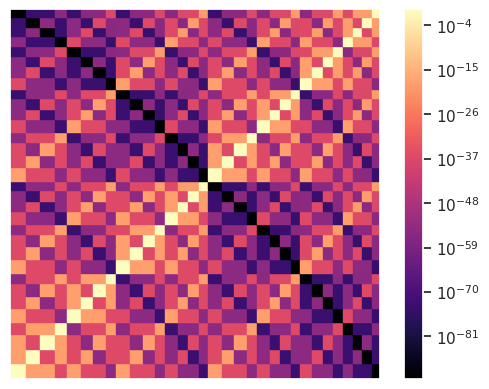

In [11]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_individual_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/horses_individual_log_plot.pdf"
)

# Bootstrapping Stability

In [13]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'median'
)

Gathering statistics (30 runs)...


100%|██████████| 30/30 [05:32<00:00, 11.09s/it]

Bootstrapping: Resampling 100 times...


Bootstrapping finished in 0:00:00.312805
Energy = 8.03 (7.78, 8.80)
l = [0.54 (0.51, 0.57), 0.46 (0.43, 0.49)]
P = [
[0.98 (0.93, 1.00), 0.00 (0.00, 0.02)],

[0.00 (0.00, 0.02), 0.78 (0.73, 0.82)]
]


In [14]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 517,
  'expected_count': 518.0,
  'MRE': 0.0019342359767891683,
  'expected_count_ci_low': 512.475,
  'expected_count_ci_high': 536.05,
  'MRE_ci_low': 0.0,
  'MRE_ci_high': 0.03553438103691325},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 694,
  'expected_count': 2646.0,
  'MRE': 0.7377173091458806,
  'expected_count_ci_low': 2509.175,
  'expected_count_ci_high': 2983.575,
  'MRE_ci_low': 0.7233843226527585,
  'MRE_ci_high': 0.7673810861663228},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 577,
  'expected_count': 576.0,
  'MRE': 0.0034662045060658577,
  'expected_count_ci_low': 556.375,
  'expected_count_ci_high': 593.0,
  'MRE_ci_low': 0.0,
  'MRE_ci_high': 0.04805025996533782},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0

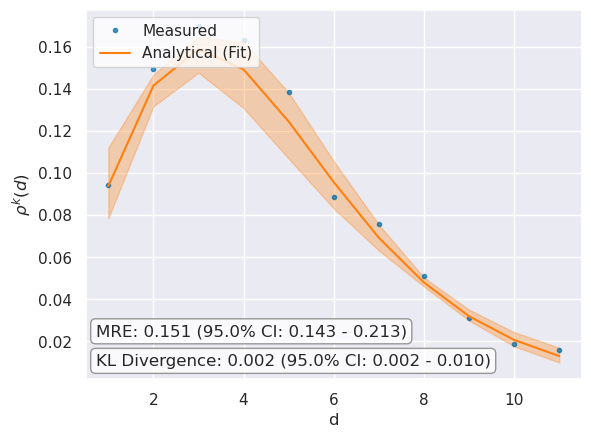

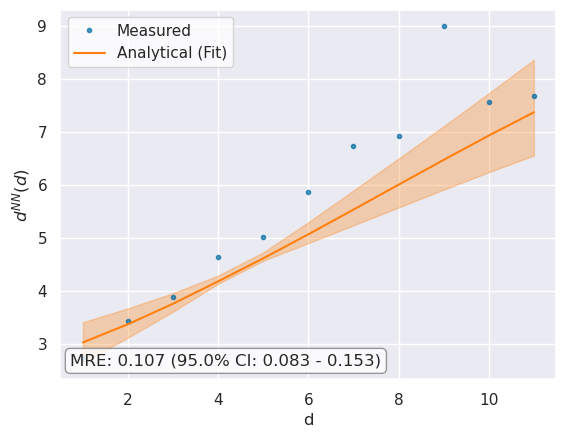

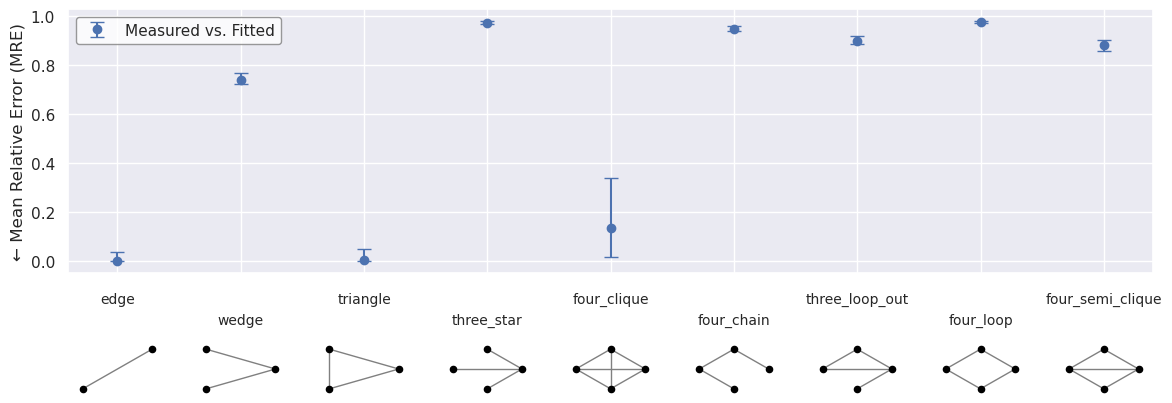

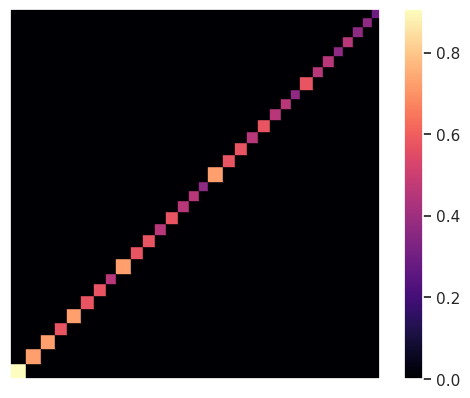

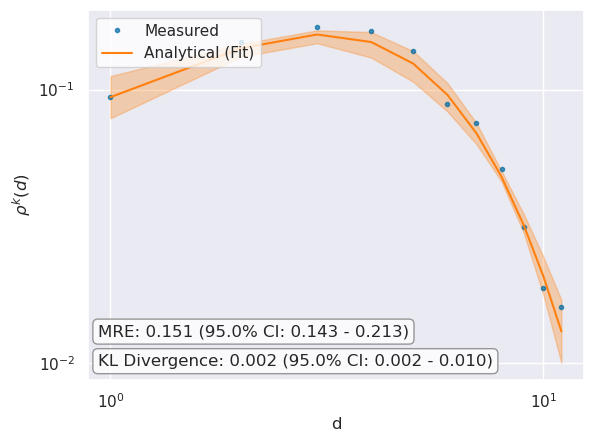

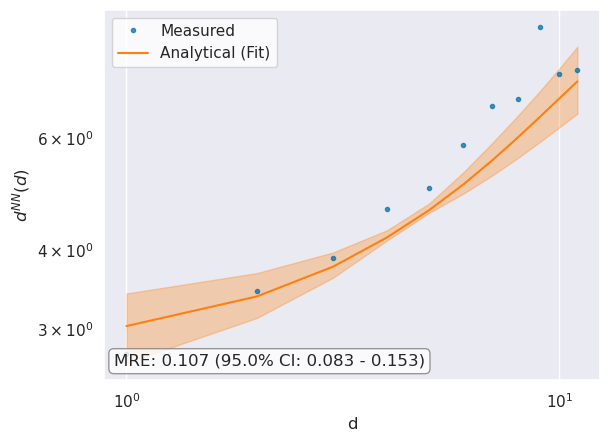

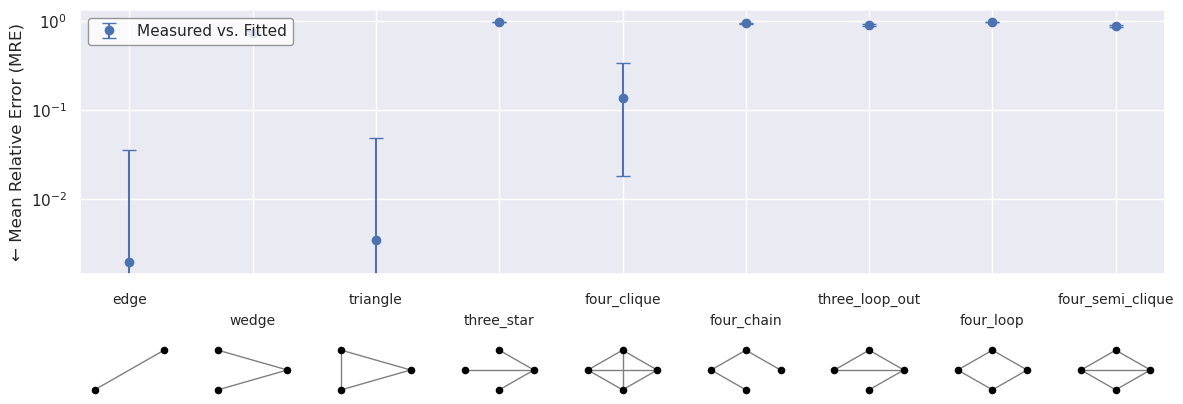

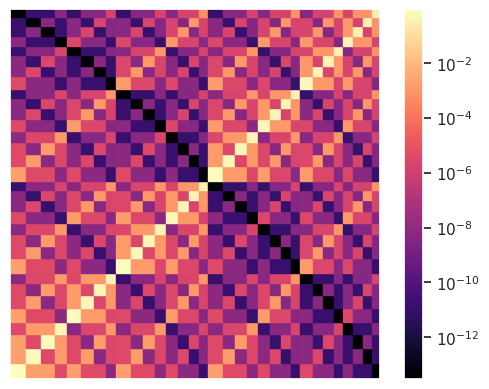

In [15]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/horses_individual_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/horses_individual_log_plot.pdf"
)

In [16]:
import pickle
with open('./test_networks/horses_individual_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)

# Generate Variants

Initializing...
0.0005819797515869141
Calculating betweenness...
Done.
Calculating node positions...
Done.


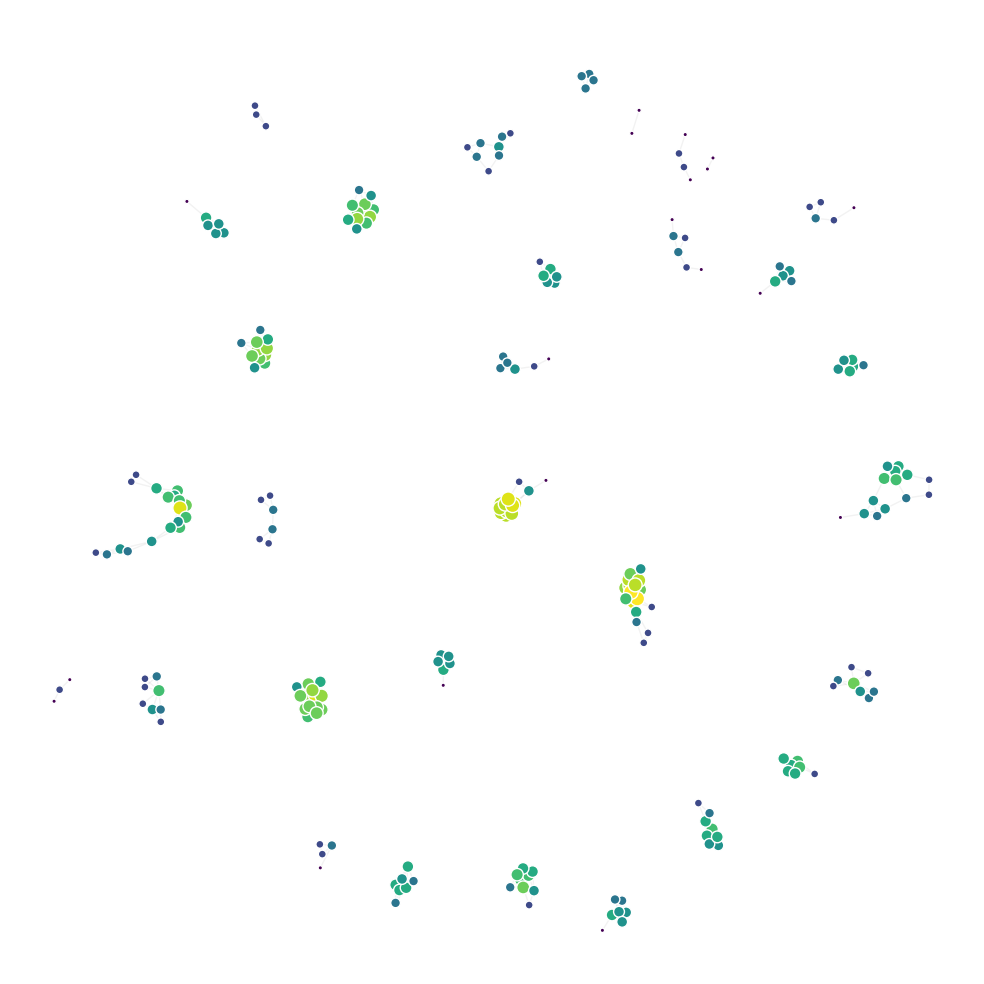

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 727.72it/s]

Refining network structure...


Calculating betweenness...
Done.
Calculating node positions...
Done.


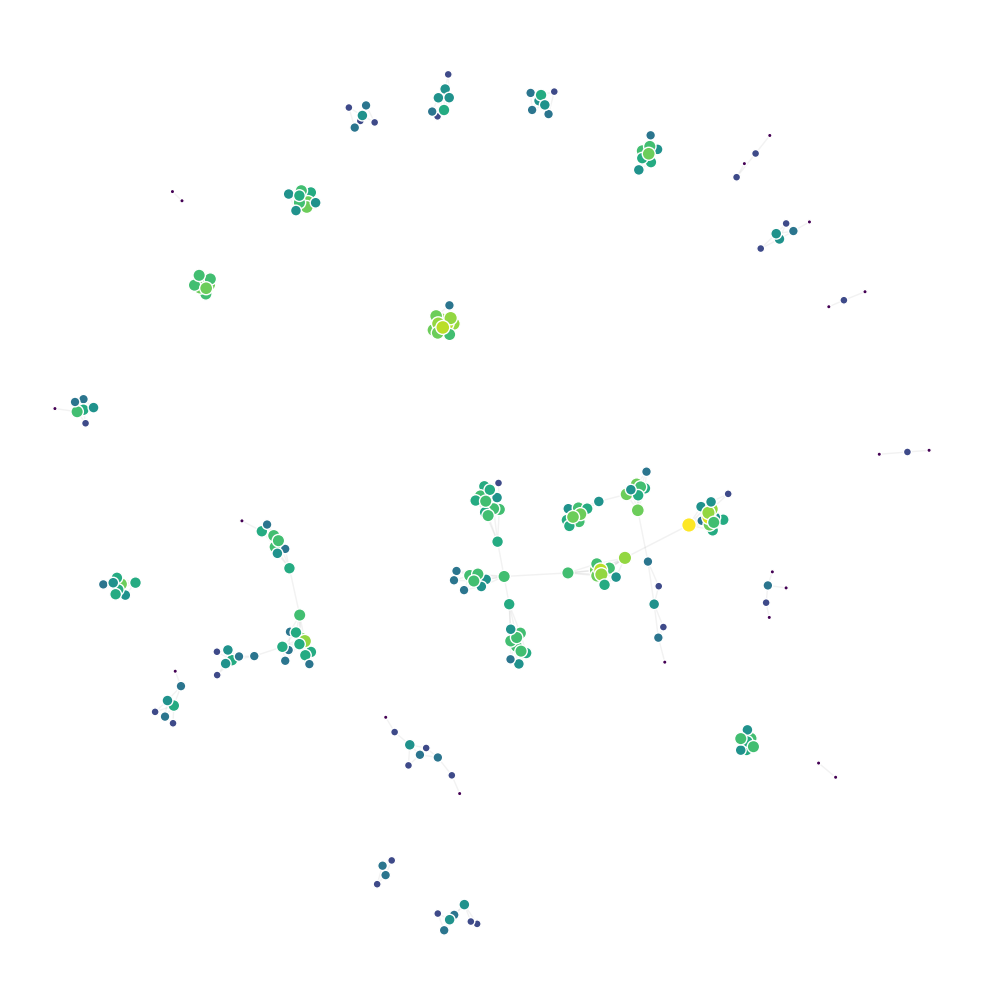

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 1125.32it/s]

Refining network structure...


Calculating betweenness...
Done.
Calculating node positions...
Done.


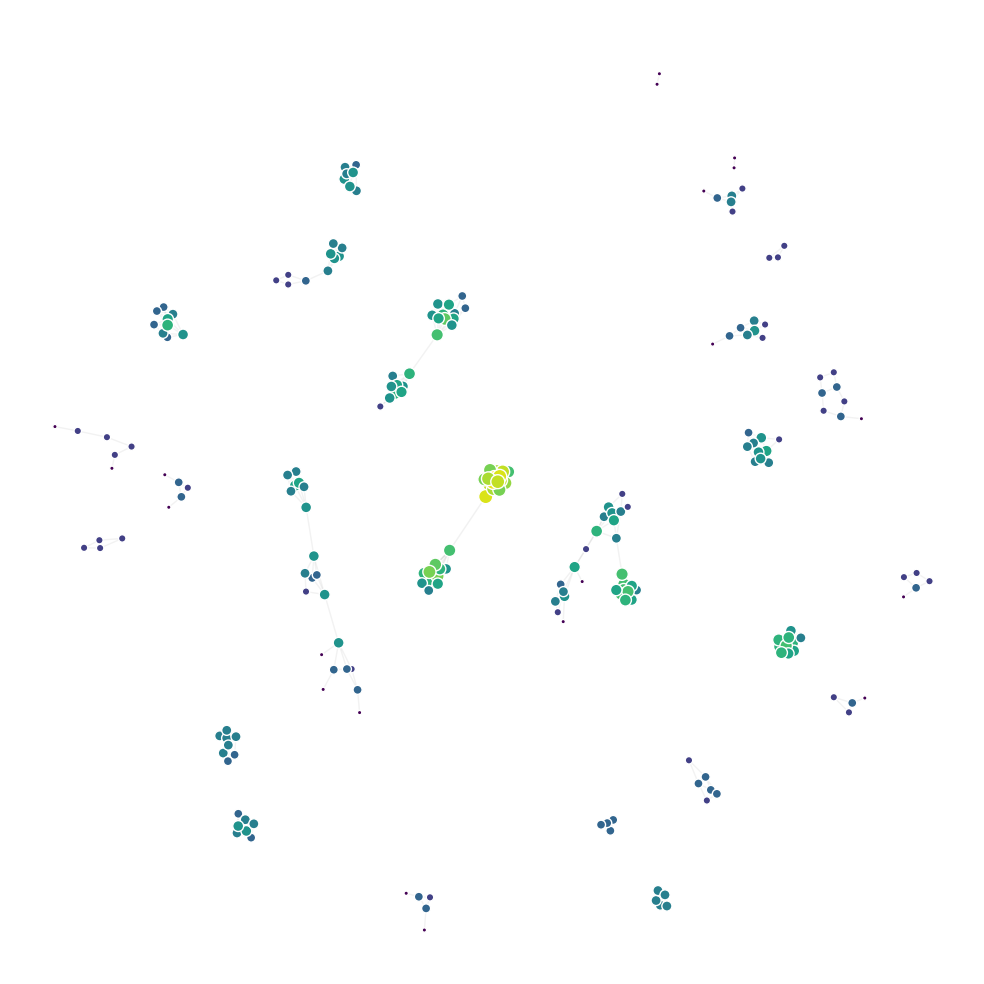

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 926.41it/s]

Refining network structure...


Calculating betweenness...
Done.
Calculating node positions...
Done.


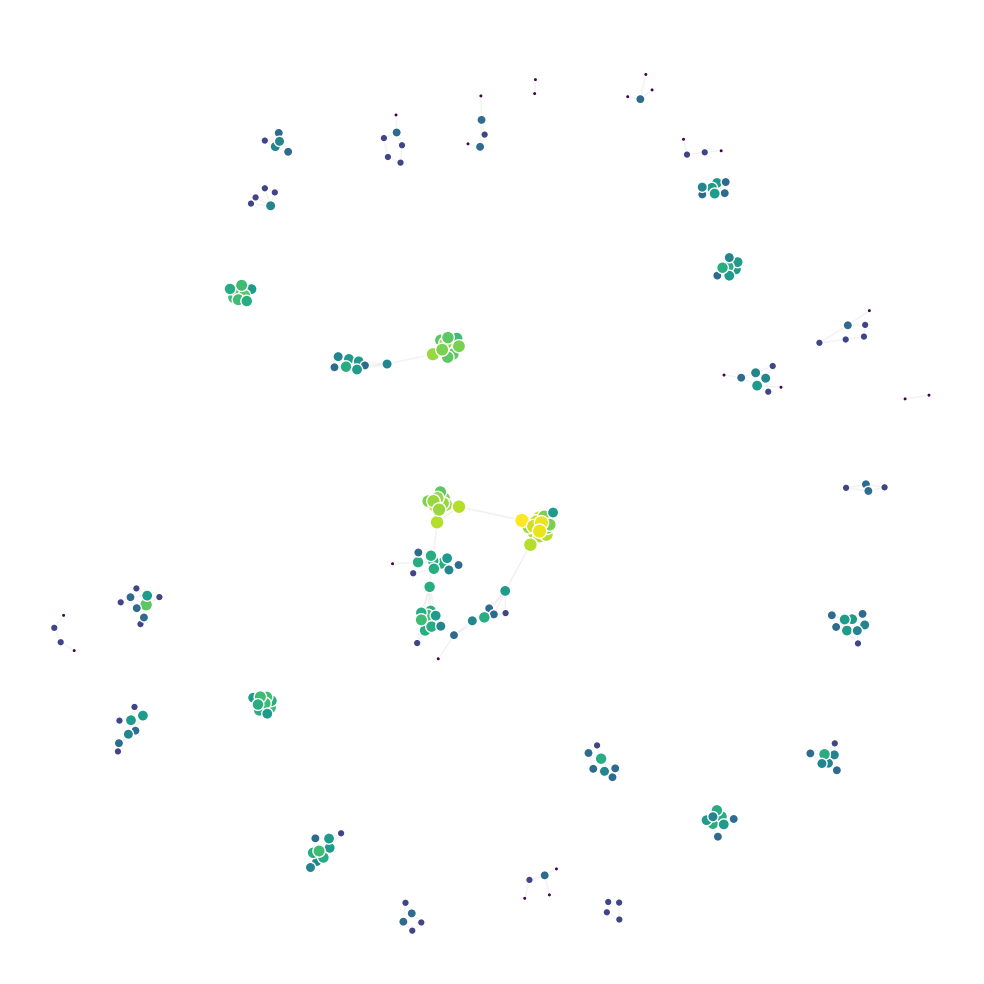

In [17]:
mfnf.generate_variants(
    plot_options = {
        'layout_func': nx.spring_layout,
        'figsize': (10,10),
        'filename':  "figures/horses_individual_variants.pdf"
    },
    filename = "variant_networks/horses_individual_variants.graphml"
)

# Comparison with Benson et. al's method.

In [14]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_star', 'matrix': np.array([[0, 1, 1, 1, 1],[1, 0, 0, 0, 0],[1, 0, 0, 0, 0],[1, 0, 0, 0, 0],[1, 0, 0, 0, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001,
        5: 0.000001,
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 6000,
    weights = {
        'rho':0,
        'deg_nn':0,
        'motifs':1
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 1 user-provided motifs.
Adding custom motif 'four_star'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.003049
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.008487
Counting motifs of size 5... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.022155


In [15]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 517},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 694},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 577},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 133},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 468},
 {'name': 'four_star',
  'matrix': array([[0, 1, 1, 1, 1],
         [1, 0, 0, 0, 0],
         [1, 0, 0, 0, 0],
         [1, 0, 0, 0, 0],
         [1, 0, 0, 0, 0]]),
  'size': 5,
  'count': 29}]

In [16]:
k2 = np.log(len(G))/np.log(2)
print(k2)
k3 = np.log(len(G))/np.log(3)
print(k3)

7.882643049361841
4.973394036625629


In [17]:
mfnf.find_P_l(2,7,one_shot = True)

Energy: 3.0259202216143897
KL-divergence: 0.09712635209120707
KLD augumented energy: 3.0259202216143897


In [20]:
P2 = mfnf.P
L2 = mfnf.l

In [21]:
mfnf.find_P_l(3,5,one_shot = True)

Energy: 3.0818301237069914
KL-divergence: 0.08858206339714836
KLD augumented energy: 3.0818301237069914


In [22]:
P3 = mfnf.P
L3 = mfnf.l

In [23]:
mfnf_no_fit = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9,
        'triangle':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.003307
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.008964


In [28]:
mfnf_no_fit.P = P2
mfnf_no_fit.l = L2
mfnf_no_fit.k = 7
mfnf_no_fit._calculate_metrics()

In [30]:
mfnf_no_fit.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 517,
  'expected_count': 507,
  'MRE': 0.019342359767891684},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 694,
  'expected_count': 4602,
  'MRE': 0.8491960017383746},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 577,
  'expected_count': 508,
  'MRE': 0.1195840554592721},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 133,
  'expected_count': 19821,
  'MRE': 0.99328994500782},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 468,
  'expected_count': 490,
  'MRE': 0.044897959183673466},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1,

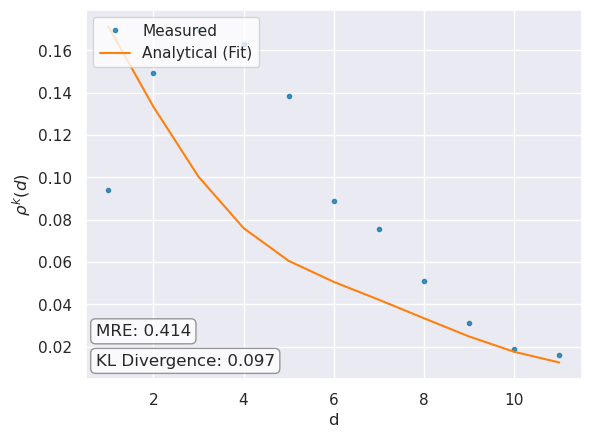

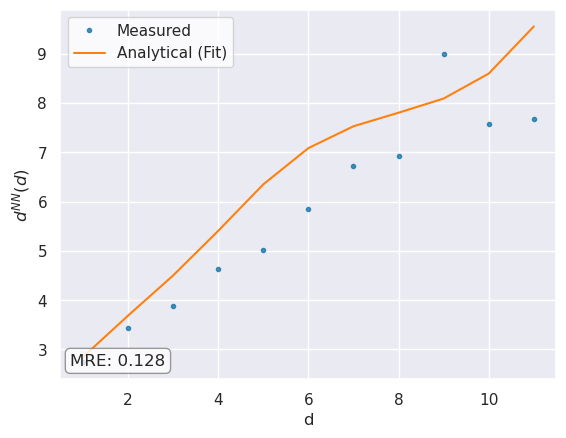

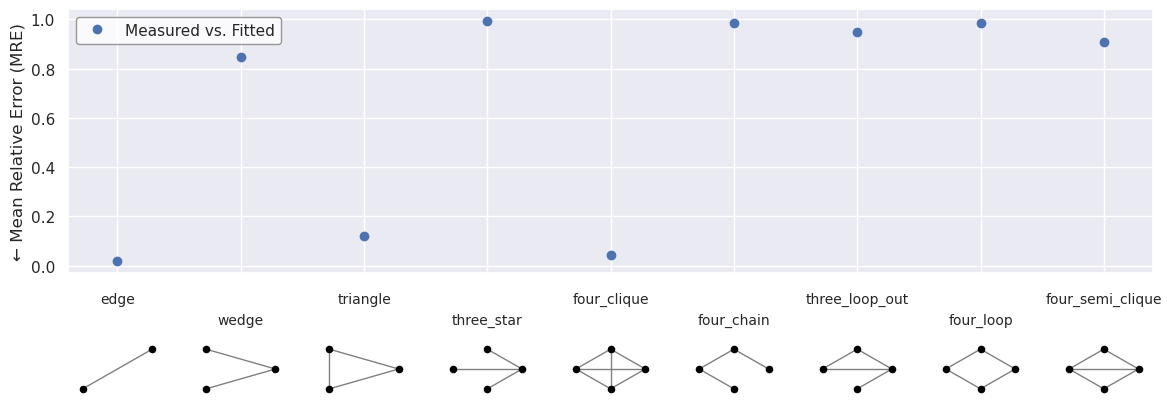

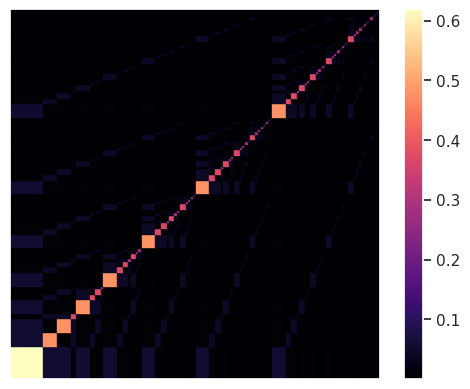

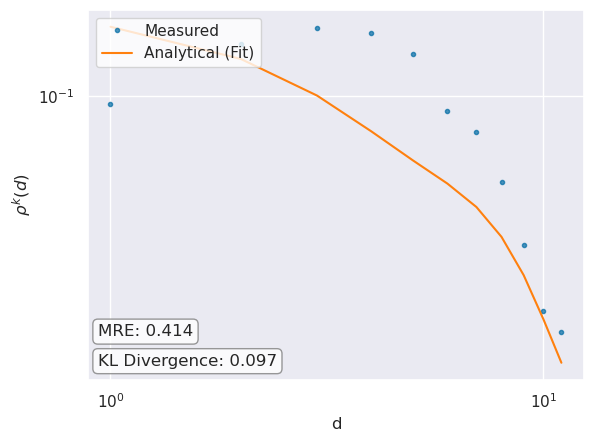

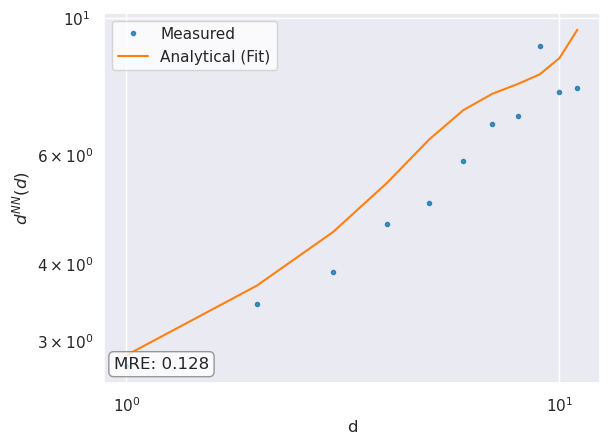

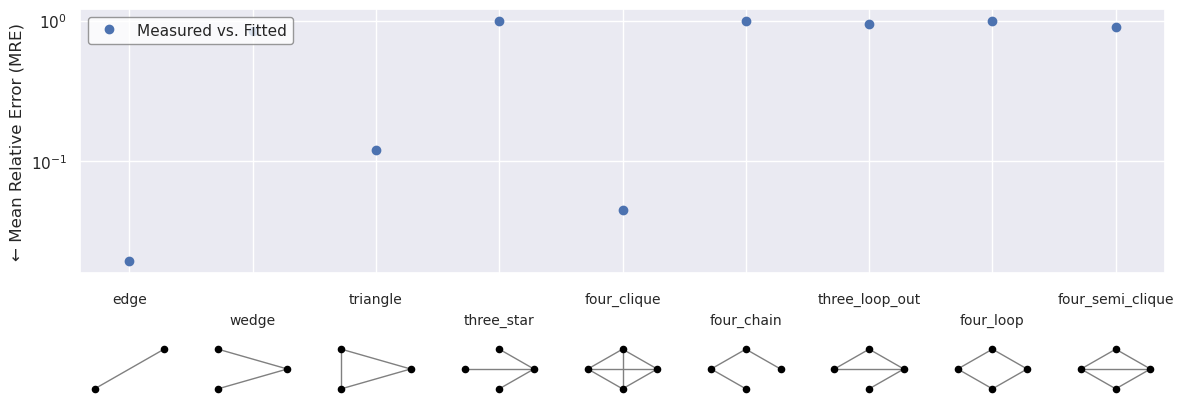

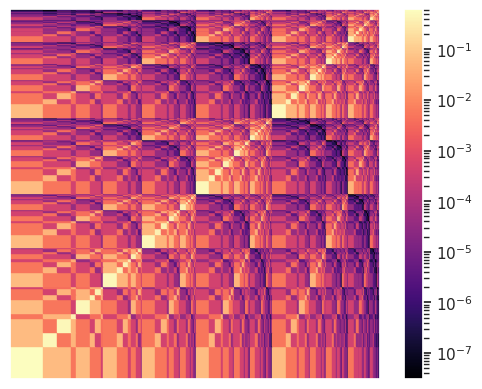

In [32]:
mfnf_no_fit.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/horses_individual_benson_2_plot.pdf"
)
mfnf_no_fit.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/horses_individual_benson_2_log_plot.pdf"
)

In [33]:
mfnf_no_fit.P = P3
mfnf_no_fit.l = L3
mfnf_no_fit.k = 5
mfnf_no_fit._calculate_metrics()

In [34]:
mfnf_no_fit.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 517,
  'expected_count': 589,
  'MRE': 0.12224108658743633},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 694,
  'expected_count': 6127,
  'MRE': 0.8867308633915456},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 577,
  'expected_count': 580,
  'MRE': 0.005172413793103448},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 133,
  'expected_count': 28306,
  'MRE': 0.9953013495372006},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 468,
  'expected_count': 434,
  'MRE': 0.07264957264957266},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [

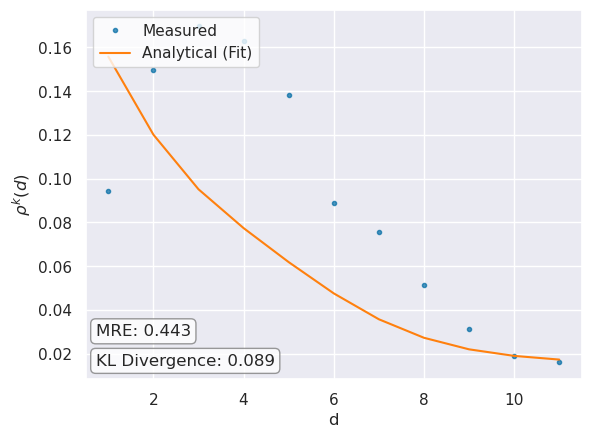

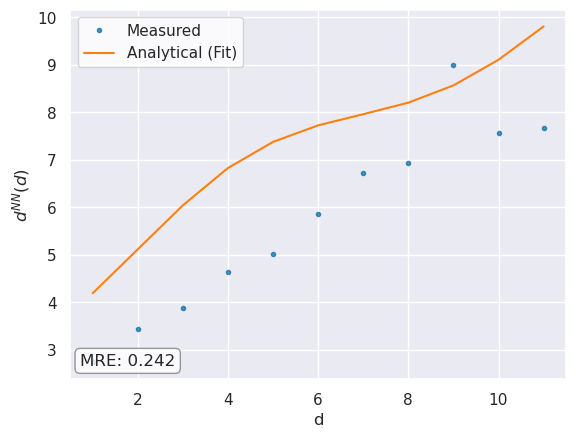

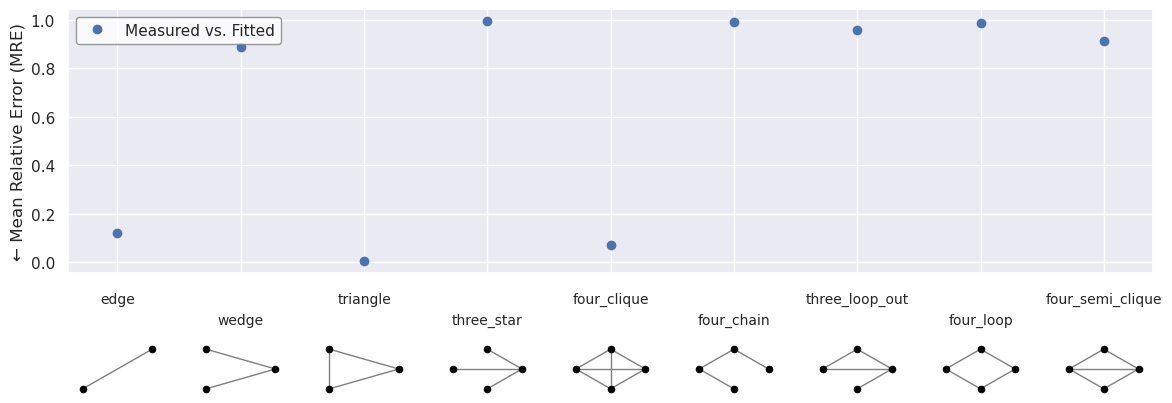

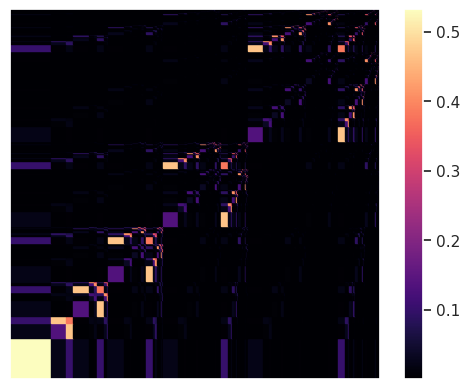

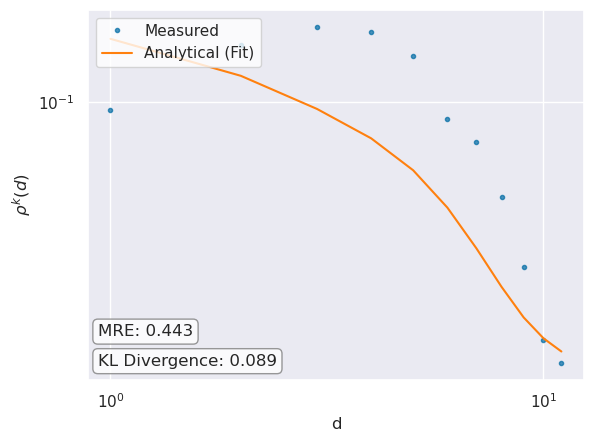

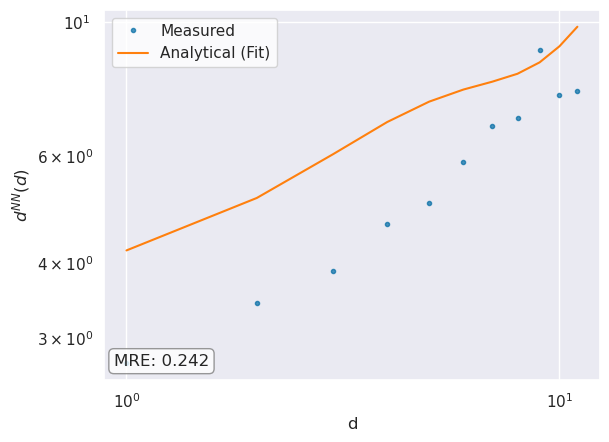

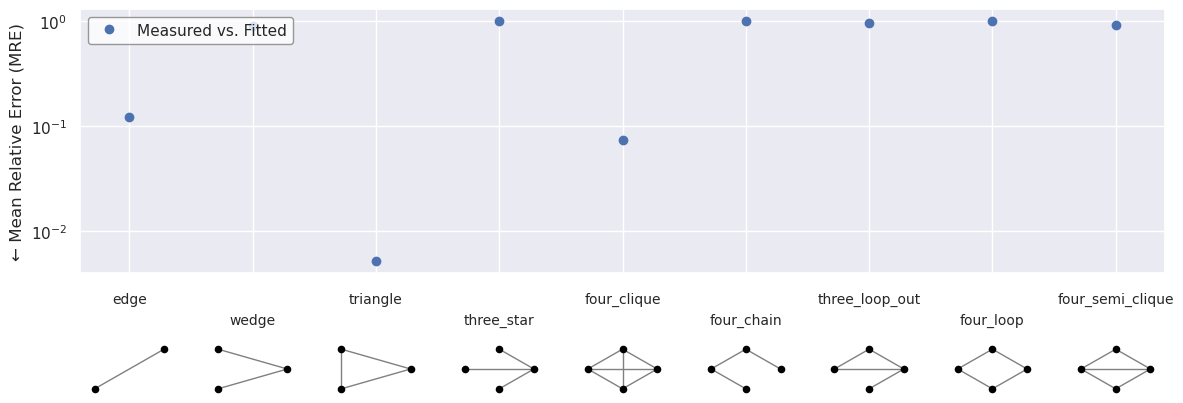

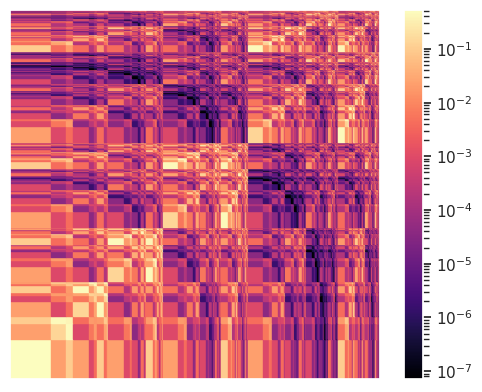

In [35]:
mfnf_no_fit.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/horses_individual_benson_3_plot.pdf"
)
mfnf_no_fit.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/horses_individual_benson_3_log_plot.pdf"
)